In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding = 'euc-kr')

In [2]:
df = pd.read_csv('../data/port_all.csv', encoding='utf-8-sig')

display(df.head())

,연도,부두,물동량_천TEU,하역능력_천TEU,가동률_pct,안벽길이_m,접안선석수,CC수,운영개시연도,운영연수,자동화수준_현재_초안,자동화수준_설명,신항여부,완전자동화여부
0,2017,신항2부두,4531,3790,119.6,2000,6,22,2006,11,1,부분 자동화(분석용 초안),1,0
1,2017,신항1부두,2689,2090,128.7,1200,3,12,2010,7,1,부분 자동화(분석용 초안),1,0
2,2017,신선대부두,2261,2236,101.1,1500,5,15,1991,26,0,유인 중심(분석용 초안),0,0
3,2017,신항3부두,2219,2310,96.1,1100,4,12,2009,8,2,야드 자동화(분석용 초안),1,0
4,2017,신항4부두,2069,1930,107.2,1150,4,12,2010,7,2,야드 자동화(분석용 초안),1,0


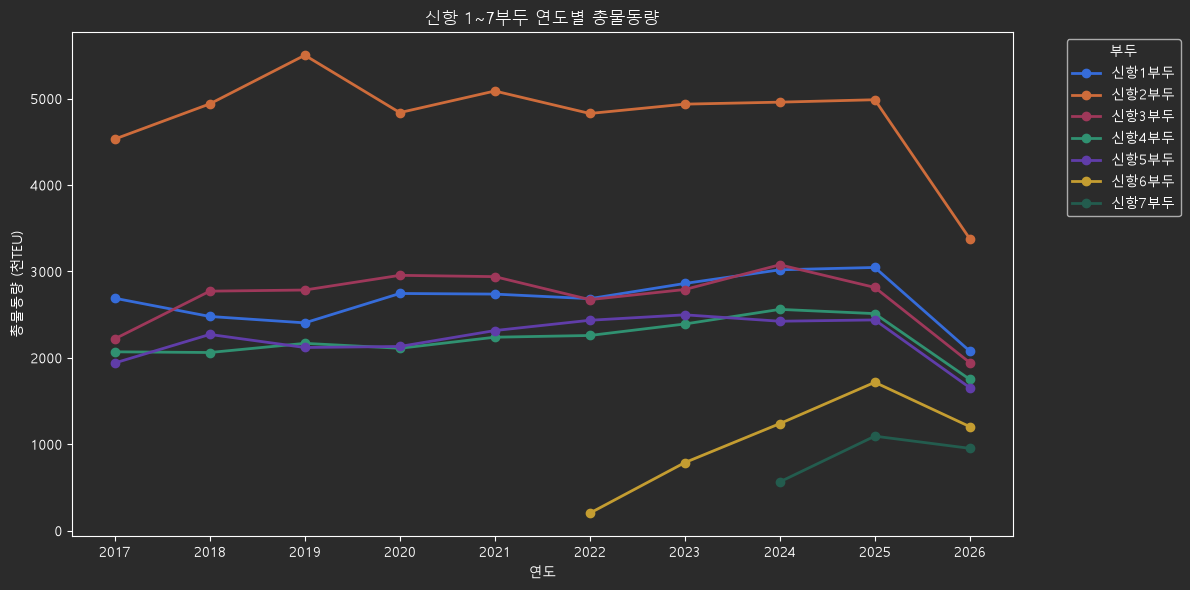

부두,신항1부두,신항2부두,신항3부두,신항4부두,신항5부두,신항6부두,신항7부두
연도,,,,,,,
2017,2689.0,4531.0,2219.0,2069.0,1940.0,NaN,NaN
2018,2478.0,4938.0,2771.0,2061.0,2270.0,NaN,NaN
2019,2404.0,5501.0,2784.0,2167.0,2119.0,NaN,NaN
2020,2744.0,4837.0,2954.0,2110.0,2131.0,NaN,NaN
2021,2737.0,5087.0,2939.0,2238.0,2315.0,NaN,NaN
2022,2684.0,4827.0,2673.0,2258.0,2434.0,202.0,NaN
2023,2860.0,4935.0,2790.0,2391.0,2497.0,787.0,NaN
2024,3018.0,4958.0,3076.0,2560.0,2423.0,1238.0,564.0
2025,3045.0,4986.0,2814.0,2511.0,2438.0,1716.0,1093.0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일 불러오기
df = pd.read_csv('../data/port_all.csv', encoding='utf-8-sig')

# 2. 신항 1~7부두 선택
target_ports = [
    '신항1부두',
    '신항2부두',
    '신항3부두',
    '신항4부두',
    '신항5부두',
    '신항6부두',
    '신항7부두'
]

df_filtered = df[df['부두'].isin(target_ports)]

# 3. 연도별 부두별 총물동량 합계
grouped = df_filtered.groupby(
    ['연도', '부두']
)['물동량_천TEU'].sum().reset_index()

# 4. 그래프용 데이터 변환 (빠진 부분)
pivot_df = grouped.pivot(
    index='연도',
    columns='부두',
    values='물동량_천TEU'
)

# 5. 부두 순서 지정
pivot_df = pivot_df.reindex(columns=target_ports)

# 6. 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 7. 라인그래프 생성
pivot_df.plot(
    kind='line',
    marker='o',
    figsize=(12, 6),
    linewidth=2
)

# 8. 그래프 설정
plt.title('신항 1~7부두 연도별 총물동량')
plt.xlabel('연도')
plt.ylabel('총물동량 (천TEU)')

# 모든 연도 표시
plt.xticks(ticks=pivot_df.index, rotation=0)

plt.legend(
    title='부두',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

# 9. 데이터 표 출력
display(pivot_df)

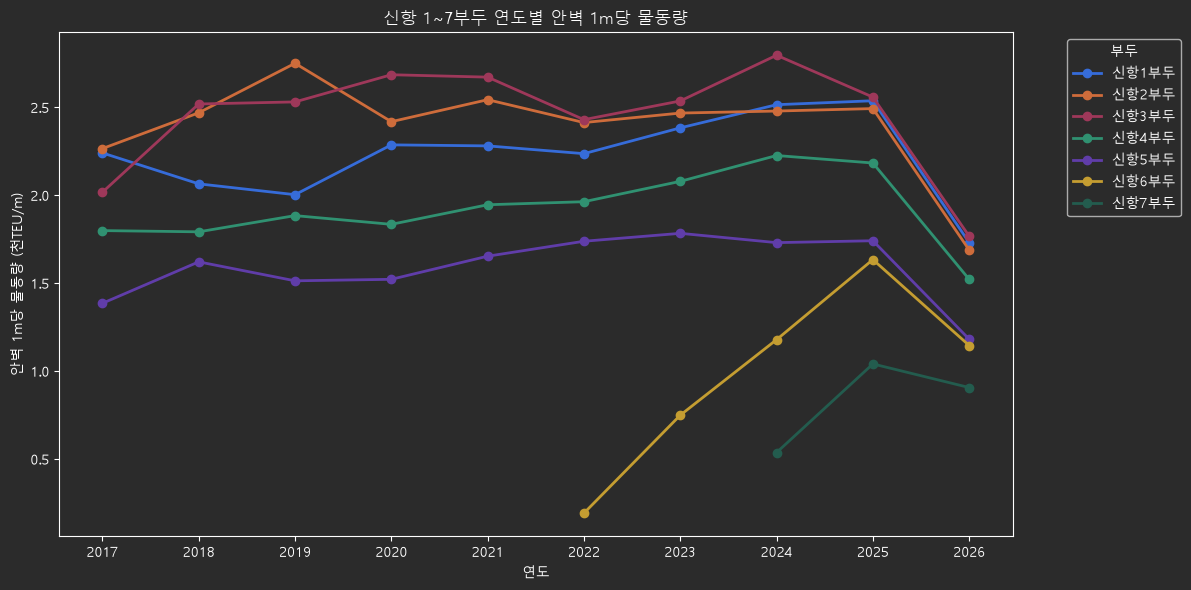

,연도,부두,총물동량,안벽길이,안벽당_물동량
0,2017,신항1부두,2689,1200,2.240833
1,2017,신항2부두,4531,2000,2.265500
2,2017,신항3부두,2219,1100,2.017273
3,2017,신항4부두,2069,1150,1.799130
4,2017,신항5부두,1940,1400,1.385714
5,2018,신항1부두,2478,1200,2.065000
6,2018,신항2부두,4938,2000,2.469000
7,2018,신항3부두,2771,1100,2.519091
8,2018,신항4부두,2061,1150,1.792174
9,2018,신항5부두,2270,1400,1.621429


In [4]:

# 2. 신항 1~7부두 선택
target_ports = [
    '신항1부두',
    '신항2부두',
    '신항3부두',
    '신항4부두',
    '신항5부두',
    '신항6부두',
    '신항7부두'
]

df_filtered = df[df['부두'].isin(target_ports)].copy()

# 3. 연도별, 부두별 물동량 및 안벽길이 정리
grouped = df_filtered.groupby(['연도', '부두']).agg(
    총물동량=('물동량_천TEU', 'sum'),
    안벽길이=('안벽길이_m', 'first')
).reset_index()

# 4. 안벽 1m당 물동량 계산
grouped['안벽당_물동량'] = (
    grouped['총물동량'] / grouped['안벽길이']
)

# 5. 그래프용 데이터 변환
pivot_df = grouped.pivot(
    index='연도',
    columns='부두',
    values='안벽당_물동량'
)

# 6. 부두 순서 지정
pivot_df = pivot_df.reindex(columns=target_ports)

# 7. 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 8. 그래프 생성
pivot_df.plot(
    kind='line',
    marker='o',
    figsize=(12, 6),
    linewidth=2
)

# 9. 그래프 설정
plt.title('신항 1~7부두 연도별 안벽 1m당 물동량')
plt.xlabel('연도')
plt.ylabel('안벽 1m당 물동량 (천TEU/m)')
plt.xticks(rotation=0)
plt.xticks(ticks=pivot_df.index, rotation=0)
plt.legend(
    title='부두',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

# 10. 계산 결과 표 출력
display(grouped)